In [7]:
# importing libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb
import xgboost as xgb
import catboost as cb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import roc_auc_score

In [8]:
#merge data

client= pd.read_csv("Client.csv")
record= pd.read_csv("Record.csv")
df= pd.merge(client,record,on='Customer_ID', how='inner')

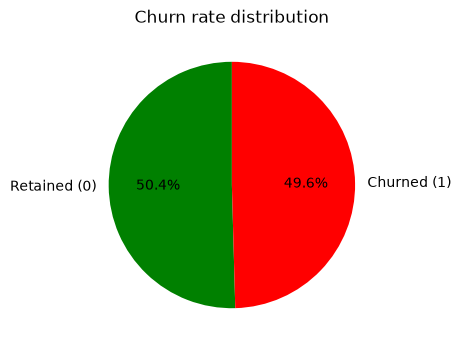

/tmp/ipykernel_30685/765201320.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='churn', y='totrev', data=df, showfliers=False, ax=ax, palette=['green', 'red'])


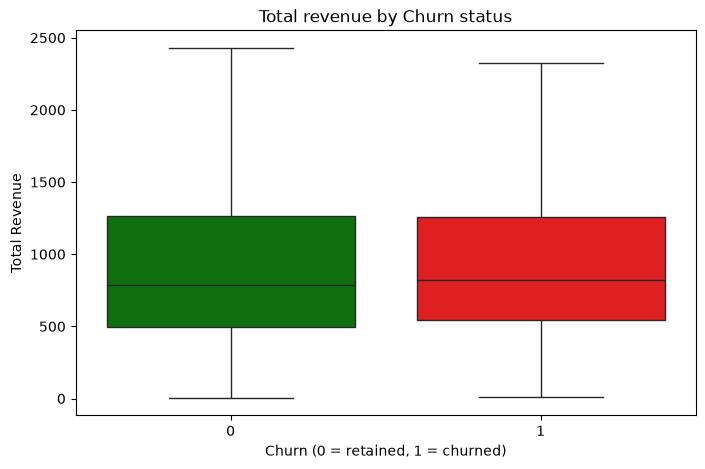

In [9]:
# EDA

fig, ax = plt.subplots(figsize=(6, 4))
df['churn'].value_counts().sort_index().plot.pie(autopct='%1.1f%%', colors=['green', 'red'], startangle=90, ax=ax, labels=['Retained (0)', 'Churned (1)'])
ax.set_title('Churn rate distribution')
ax.set_ylabel('')
plt.show()
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(x='churn', y='totrev', data=df, showfliers=False, ax=ax, palette=['green', 'red'])
ax.set_title('Total revenue by Churn status')
ax.set_xlabel('Churn (0 = retained, 1 = churned)')
ax.set_ylabel('Total Revenue')
plt.show()

In [10]:
#feature engineering

LEGACY = ['monthly_clv', 'overage_revenue_ratio', 'cost_per_minute', 'revenue_to_mrc_ratio','drop_block_rate', 'unanswered_rate', 'custcare_rate', 'mou_drop_ratio','rev_drop_ratio', 'device_age_ratio', 'active_lines_ratio']
def sdiv(a, b):
    return a / b.where(b > 0)
def flag(src, cond):
    return cond.astype(float).where(src.notna())
def engineer_features(df):
    if 'completion_rate' in df.columns:
        return df
    d = df.drop(columns=LEGACY, errors='ignore')
    f = {}
    for k in ('mou', 'qty', 'rev'):
        prior3 = 2 * d[f'avg6{k}'] - d[f'avg3{k}']
        f[f'{k}_recent_vs_prior'] = sdiv(d[f'avg3{k}'], prior3)
        f[f'{k}_recent_minus_prior'] = d[f'avg3{k}'] - prior3
        f[f'{k}_3_vs_life'] = sdiv(d[f'avg3{k}'], d[f'avg{k}'])
    f['mou_change_rel'] = sdiv(d['change_mou'], d['avg6mou'])
    f['rev_change_rel'] = sdiv(d['change_rev'], d['avg6rev'])
    f['rev_per_min'] = sdiv(d['totrev'], d['totmou'])
    f['rev_per_min_recent'] = sdiv(d['avg3rev'], d['avg3mou'])
    f['price_per_min_trend'] = sdiv(f['rev_per_min_recent'], sdiv(d['avgrev'], d['avgmou']))
    f['avg_monthly_rev'] = sdiv(d['totrev'], d['months'])
    f['mou_per_call'] = sdiv(d['totmou'], d['totcalls'])
    f['mou_per_mrc_dollar'] = sdiv(d['mou_Mean'], d['totmrc_Mean'])
    f['overage_rev_share'] = sdiv(d['ovrrev_Mean'], d['rev_Mean'])
    f['overage_min_share'] = sdiv(d['ovrmou_Mean'], d['mou_Mean'])
    f['data_rev_share'] = sdiv(d['da_Mean'], d['rev_Mean'])
    f['roam_share'] = sdiv(d['roam_Mean'], d['mou_Mean'])
    f['has_overage'] = flag(d['ovrrev_Mean'], d['ovrrev_Mean'] > 0)
    f['rev_minus_mrc'] = d['rev_Mean'] - d['totmrc_Mean']
    f['rev_per_line'] = sdiv(d['rev_Mean'], d['actvsubs'])
    f['mrc_per_line'] = sdiv(d['totmrc_Mean'], d['actvsubs'])
    att = d['attempt_Mean']
    bad = d['drop_blk_Mean'] + d['unan_vce_Mean'] + d['unan_dat_Mean']
    f['completion_rate'] = sdiv(d['complete_Mean'], att)
    f['drop_rate'] = sdiv(d['drop_vce_Mean'] + d['drop_dat_Mean'], att)
    f['block_rate'] = sdiv(d['blck_vce_Mean'] + d['blck_dat_Mean'], att)
    f['unanswered_rate'] = sdiv(d['unan_vce_Mean'] + d['unan_dat_Mean'],d['plcd_vce_Mean'] + d['plcd_dat_Mean'])
    f['bad_events']=bad
    f['bad_events_per_min'] = sdiv(bad, d['mou_Mean'])
    f['custcare_rate'] = sdiv(d['custcare_Mean'], d['comp_vce_Mean'])
    f['custcare_per_min'] = sdiv(d['custcare_Mean'], d['mou_Mean'])
    f['cc_min_share']=sdiv(d['cc_mou_Mean'], d['mou_Mean'])
    f['has_custcare'] = flag(d['custcare_Mean'], d['custcare_Mean'] > 0)
    f['custcare_per_bad_event'] = sdiv(d['custcare_Mean'], bad)
    f['data_call_share'] = sdiv(d['comp_dat_Mean'], d['comp_vce_Mean'] + d['comp_dat_Mean'])
    f['peak_min_share'] = sdiv(d['mou_peav_Mean'], d['mou_peav_Mean'] + d['mou_opkv_Mean'])
    f['inbound_min_share'] = sdiv(d['mou_rvce_Mean'], d['mou_Mean'])
    f['min_per_completed_call'] = sdiv(d['mou_cvce_Mean'], d['comp_vce_Mean'])
    f['short_inbound_share'] = sdiv(d['inonemin_Mean'], d['recv_vce_Mean'])
    f['vas_adoption'] = ((d['callfwdv_Mean'] > 0).astype(int)+ (d['callwait_Mean'] > 0).astype(int)+ (d['threeway_Mean'] > 0).astype(int))
    eq, m = d['eqpdays'], d['months']
    f['eqp_over_1y'] = flag(eq, eq > 365)
    f['eqp_over_2y'] = flag(eq, eq > 730)
    f['eqp_new']=flag(eq, eq < 90)
    f['eqp_mod_365'] = eq % 365
    f['device_age_ratio'] = sdiv(eq, m * 30)
    f['phone_changes_per_year'] = sdiv(d['phones'], m / 12)
    f['hnd_price_vs_rev'] = sdiv(d['hnd_price'], d['avgrev'])
    f['months_mod_12'] = m % 12
    f['dist_to_12m_cycle'] = (m - 12 * np.round(m / 12)).abs()
    f['inactive_lines'] = d['uniqsubs'] - d['actvsubs']
    f['active_lines_ratio'] = sdiv(d['actvsubs'], d['uniqsubs'])
    f['crclscod_grade'] = d['crclscod'].fillna('Unknown').astype(str).str[0]
    for c in ['area', 'crclscod', 'prizm_social_one', 'ethnic']:
        key = d[c].fillna('Unknown').astype(str)
        f[f'{c}_freq'] = key.map(key.value_counts(normalize=True))
    for g in ['area', 'crclscod']:
        key = d[g].fillna('Unknown').astype(str)
        for c in ['rev_Mean', 'mou_Mean', 'eqpdays']:
            f[f'{c}_vs_{g}'] = d[c] - d.groupby(key)[c].transform('mean')
    for c in ['rev_Mean', 'mou_Mean', 'eqpdays']:
        f[f'{c}_pctrank'] = d[c].rank(pct=True)
    f['n_missing'] = d.isna().sum(axis=1)
    new = pd.DataFrame(f, index=d.index).replace([np.inf, -np.inf], np.nan)
    return pd.concat([d.drop(columns=new.columns.intersection(d.columns)), new], axis=1)
df = engineer_features(df)
print(df.head(500).to_string(index=False))

 uniqsubs  actvsubs new_cell crclscod asl_flag  totcalls        totmou   totrev   adjrev    adjmou  adjqty  avgrev  avgmou  avgqty  avg3mou  avg3qty  avg3rev  avg6mou  avg6qty  avg6rev prizm_social_one                          area dualband refurb_new  hnd_price  phones  models hnd_webcap  truck  rv ownrent  lor dwlltype marital  adults infobase  income  numbcars HHstatin dwllsize  forgntvl ethnic kid0_2 kid3_5 kid6_10 kid11_15 kid16_17 creditcd  eqpdays  Customer_ID  rev_Mean  mou_Mean  totmrc_Mean  da_Mean  ovrmou_Mean  ovrrev_Mean  vceovr_Mean  datovr_Mean  roam_Mean  change_mou  change_rev  drop_vce_Mean  drop_dat_Mean  blck_vce_Mean  blck_dat_Mean  unan_vce_Mean  unan_dat_Mean  plcd_vce_Mean  plcd_dat_Mean  recv_vce_Mean  recv_sms_Mean  comp_vce_Mean  comp_dat_Mean  custcare_Mean  ccrndmou_Mean  cc_mou_Mean  inonemin_Mean  threeway_Mean  mou_cvce_Mean  mou_cdat_Mean  mou_rvce_Mean  owylis_vce_Mean  mouowylisv_Mean  iwylis_vce_Mean  mouiwylisv_Mean  peak_vce_Mean  peak_dat_Mean  mo

In [ ]:
#data preprocessing

encoder=OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
drop_cols=['recv_sms_Mean','iwylis_vce_Mean','Customer_ID','ownrent']
y=df['churn']
x=df.drop(['churn']+ drop_cols,axis=1)
na = x.isna().mean().sort_values(ascending=False)
cands = na[na >= 0.85].index.tolist()
print(cands)
x_cat=x.copy()
cat_cols= x.select_dtypes(include=['object']).columns.tolist()
num_cols= x.select_dtypes(exclude=['object']).columns.tolist()
x[cat_cols]=x[cat_cols].replace("NaN", "Unknown").fillna('Unknown').astype('category')
x_cat[cat_cols] = x_cat[cat_cols].fillna('Unknown').astype(str)
x[cat_cols]=encoder.fit_transform(x[cat_cols])

[]


/tmp/ipykernel_30685/3657619675.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols= x.select_dtypes(include=['object']).columns.tolist()


In [13]:
# feature importance

lgbModel = lgb.LGBMClassifier(n_estimators=1500, learning_rate=0.04, num_leaves=20,min_child_samples=100, colsample_bytree=0.5, subsample=0.8,subsample_freq=1, reg_lambda=7, random_state=42, verbose=-1)
lgbModel.fit(x,y)
importance_df = pd.DataFrame({
    'Feature': x.columns,
    'Importance': lgbModel.feature_importances_})
zero_importance_features = importance_df[importance_df['Importance'] == 0]['Feature']
x=x.drop(columns=zero_importance_features)
x_cat=x_cat.drop(columns=zero_importance_features)

In [ ]:
skf= StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
oof_cb= np.zeros(len(y))
oof_lgb= np.zeros(len(y))
oof_xgb= np.zeros(len(y))
for fold,(tr, va) in enumerate(skf.split(x, y), 1):
    cbModel= cb.CatBoostClassifier(
        iterations=2200,
        learning_rate=0.04,
        depth=6,
        cat_features=cat_cols,
        random_state=42,
        verbose=0,task_type='GPU')
    cbModel.fit(x_cat.iloc[tr], y.iloc[tr])
    oof_cb[va] = cbModel.predict_proba(x_cat.iloc[va])[:, 1]
    lgbModel = lgb.LGBMClassifier(n_estimators=1500, learning_rate=0.04, num_leaves=20,min_child_samples=100, colsample_bytree=0.5, subsample=0.8,subsample_freq=1, reg_lambda=7, random_state=42, verbose=-1)
    lgbModel.fit(x.iloc[tr], y.iloc[tr])
    oof_lgb[va] = lgbModel.predict_proba(x.iloc[va])[:, 1]
    xgbModel = xgb.XGBClassifier(n_estimators=1100, learning_rate=0.04, max_depth=5,reg_lambda=6, random_state=42,enable_categorial=True, tree_method='hist',device='cuda')
    xgbModel.fit(x.iloc[tr], y.iloc[tr])
    oof_xgb[va] = xgbModel.predict_proba(x.iloc[va])[:, 1]
    print(f'fold {fold}/5 done')
weight_lgb = 4
weight_xgb = 2
weight_cb = 1
total_weight= weight_lgb +weight_xgb + weight_cb
oof_pre = (oof_lgb * weight_lgb + oof_xgb * weight_xgb + oof_cb * weight_cb) / total_weight
print(f'CV ROC-AUC {roc_auc_score(y, oof_pre)}')
# the final file for every costumer
FinalDataframe = pd.DataFrame()
FinalDataframe['Customer_ID']= df['Customer_ID']
FinalDataframe['churn_probability']=oof_pre
FinalDataframe['Expected_Loss_Score']= FinalDataframe['churn_probability'] * df['totrev']
FinalDataframe = FinalDataframe.sort_values(by='Expected_Loss_Score',ascending=False)
FinalDataframe = FinalDataframe.reset_index(drop=True)
FinalDataframe.to_csv('FinalDataframe.csv',index=False)

fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done
CV ROC-AUC 0.7062157393009162
